Compares: naive (yesterday), linear regression, random forest, LightGBM.
Run after forecast.py. Needs: pip install scikit-learn
Writes model_comparison.csv (long format) and prints MAE and RMSE tables.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from forecast import load_signals, build_features, mae, rmse, signals, steps_per_day, test_days

In [26]:
result = pd.DataFrame(rows)
result.to_csv("model_comparison.csv", index=False)

In [27]:
print("\nNumber of rows:", len(result))
print("\nSignals in results:")
print(result["signal"].value_counts())

print("\nFull results:")
print(result.to_string(index=False))


Number of rows: 20

Signals in results:
signal
demand    5
price     5
solar     5
wind      5
Name: count, dtype: int64

Full results:
signal             model       MAE      RMSE
demand Naive (yesterday)  5.880803  7.282002
demand Linear regression  4.163554  5.226807
demand     Random forest  4.520390  5.694441
demand          LightGBM  4.466381  5.582119
demand           XGBoost  4.450657  5.573159
 price Naive (yesterday)  5.595352 15.372080
 price Linear regression  5.064504 11.027597
 price     Random forest  3.993207 10.080734
 price          LightGBM  4.373995 10.443698
 price           XGBoost  4.465785 10.366513
 solar Naive (yesterday)  5.024056  9.777840
 solar Linear regression  4.330739  7.513693
 solar     Random forest  3.548874  6.948493
 solar          LightGBM  3.596053  6.946907
 solar           XGBoost  3.614732  6.927839
  wind Naive (yesterday) 17.010950 20.689425
  wind Linear regression 10.670582 13.074524
  wind     Random forest 11.996060 14.680742
  wind  

In [28]:
table = result.pivot(index="model", columns="signal", values="MAE")
print(table)

signal               demand     price     solar       wind
model                                                     
LightGBM           4.466381  4.373995  3.596053  11.987979
Linear regression  4.163554  5.064504  4.330739  10.670582
Naive (yesterday)  5.880803  5.595352  5.024056  17.010950
Random forest      4.520390  3.993207  3.548874  11.996060
XGBoost            4.450657  4.465785  3.614732  11.916280


In [29]:
print(result["model"].unique())

<ArrowStringArray>
['Naive (yesterday)', 'Linear regression',     'Random forest',
          'LightGBM',           'XGBoost']
Length: 5, dtype: str


In [30]:
print(result["signal"].unique())

<ArrowStringArray>
['demand', 'price', 'solar', 'wind']
Length: 4, dtype: str


In [31]:
order = ['Naive (yesterday)', 'Linear regression', 'Random forest','LightGBM', 'XGBoost']
for metric in ["MAE", "RMSE"]:
    table = result.pivot(index="model", columns="signal", values=metric).loc[order, signals].round(2)
    print(f"\n{metric} on the last {test_days} days (lower is better)")
    print(table.to_string())

print("\nSanity check: the LightGBM MAE row should match forecast_metrics.csv (lgbm_MAE).")


MAE on the last 6 days (lower is better)
signal             demand  price  solar   wind
model                                         
Naive (yesterday)    5.88   5.60   5.02  17.01
Linear regression    4.16   5.06   4.33  10.67
Random forest        4.52   3.99   3.55  12.00
LightGBM             4.47   4.37   3.60  11.99
XGBoost              4.45   4.47   3.61  11.92

RMSE on the last 6 days (lower is better)
signal             demand  price  solar   wind
model                                         
Naive (yesterday)    7.28  15.37   9.78  20.69
Linear regression    5.23  11.03   7.51  13.07
Random forest        5.69  10.08   6.95  14.68
LightGBM             5.58  10.44   6.95  14.65
XGBoost              5.57  10.37   6.93  14.67

Sanity check: the LightGBM MAE row should match forecast_metrics.csv (lgbm_MAE).


In [53]:
colors = {
    "Naive (yesterday)": "#5F6F72",   # gray
    "Linear regression": "#6FA59A",  # sage green
    "Random forest": "#E8A500",      # orange
    "LightGBM": "#0D7F7C",           # teal
    "XGBoost": "#7B61FF"             # purple ← recommended
}
labels = ["Demand", "Price", "Solar", "Wind"]

In [54]:
mae_table = result.pivot(
    index="model",
    columns="signal",
    values="MAE"
)

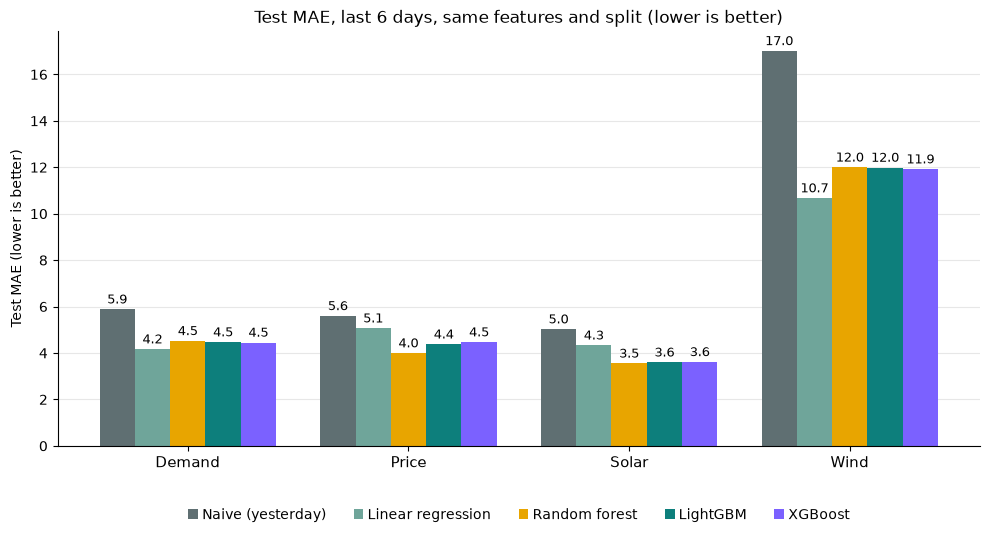

In [57]:
x = np.arange(len(signals))
width = 0.8 / len(order)

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, model in enumerate(order):
    vals = mae_table.loc[model, signals].values

    bars = ax.bar(
        x + (i - (len(order)-1)/2) * width,
        vals,
        width,
        label=model,
        color=colors[model]
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.1f}" for v in vals],
        padding=2,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel("Test MAE (lower is better)")
ax.set_title("Test MAE, last 6 days, same features and split (lower is better)")

# Legend below chart
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=5,
    frameon=False,
    fontsize=10,
    handlelength=0.7,
    handletextpad=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.subplots_adjust(bottom=0.18)

plt.savefig("model_comparison_mae.png", dpi=200, bbox_inches="tight")
plt.show()